In [2]:
import torch
import matplotlib.pyplot as plt
import numpy as np


We set the c_1, c_n with BC $u(t,0)=u(t,1)=0$ and then we are training to get the coefficients that fit the IC: $u(0,x)=sin(2\pi x)$

In [3]:
class bsplines1D:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
    

        # 1D trainable coefficients
        self.coeffs_trainable = torch.rand(n_basis-2)

        # Define the non-trainable coeff based on the Dirichlet boundary conditions.
        self.coeffs = torch.tensor([0.0,0.0])
        self.coeffs_trainable.requires_grad_()
        
        

        
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ##############Change#################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ##############Change#################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x, self.knot_x ) for i in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        

        # Adding the internal domain bsplines
        for i in range(1,(self.n_basis-1)):
            y += self.coeffs_trainable[i-1] *self.B_x[i]

        #Adding the BC domain bsplines based on the BC coefficeints
        y += self.coeffs[0]*self.B_x[0]+self.coeffs[1]*self.B_x[self.n_basis-1]

        return y

In [4]:
# Reproducable weights
torch.manual_seed(42)
# model_bc = bsplines1D(10,3)
# model_bc = bsplines1D(20,2)
model_bc = bsplines1D(20,3)

In [5]:
x = torch.linspace(0,1,1000)
y = model_bc.forward(x)
u_exact = torch.sin(2*torch.pi*x)

In [11]:
bc_coeff = torch.load('./results/diffusion/bc_coeff_20_3.pt')
model_bc.coeffs_trainable = bc_coeff
y_pred = model_bc.forward(x)

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_51500\775295050.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  bc_coeff = torch.load('./results/diffusion/bc_coeff_20_3.

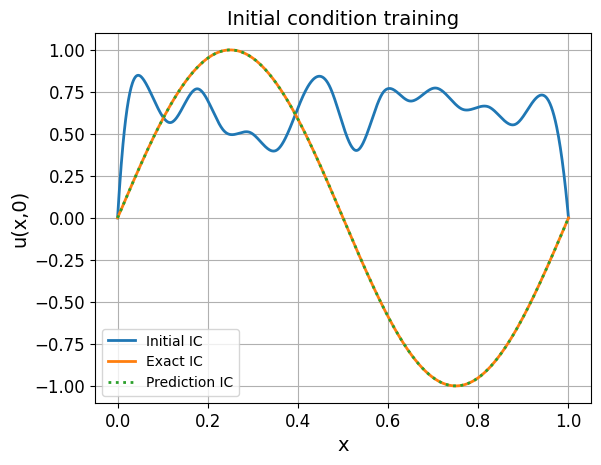

In [28]:
# figure 6
plt.plot(x,y.detach().numpy(),linewidth=2, label='Initial IC')
plt.plot(x,u_exact, linewidth=2, label='Exact IC')
plt.plot(x,y_pred,':', linewidth=2, label='Prediction IC')
# plt.plot(x_b, loss_pinn, label='PINN', alpha=0.6, color='green',linewidth=2)
plt.legend()
plt.title("Initial condition training",fontsize=14)
plt.xlabel("x",fontsize=14)
plt.ylabel("u(x,0)",fontsize=14)
plt.tick_params(axis='both', labelsize=12)
plt.grid(True)
plt.savefig("IC_Dirichlet.pdf")
plt.show()


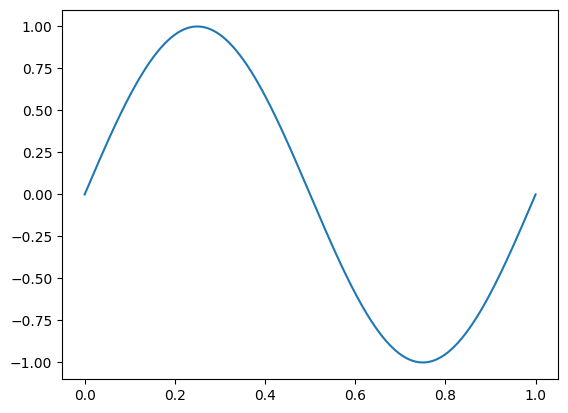

In [6]:
u_exact = torch.sin(2*torch.pi*x)
plt.plot(x,u_exact)

In [6]:
# Learning rate
learning_rate = 0.0001

# Number of iterations
epochs = 1000000
torch.manual_seed(42)
###########Changes#################
optimizer = torch.optim.Adam([model_bc.coeffs_trainable], lr=learning_rate)
###################################


# Training loop (manual gradient descent)
for epoch in range(epochs):
###########Changes#################
    optimizer.zero_grad()
###########Changes#################
    y_pred = model_bc.forward(x)
    
    # Compute model first derivative wrt x

    loss = torch.mean((y_pred-u_exact) ** 2)

    # Compute Mean Squared Error (MSE) loss
    # loss = torch.mean((y_pred - y) ** 2)
    
    # Backward pass: compute gradients
    loss.backward()
    ###########Changes#################
    optimizer.step()

    # Manually update parameters using the gradients
    # with torch.no_grad():
    #     model_bc.coeffs_trainable -= learning_rate * model_bc.coeffs_trainable.grad
    
    # # Zero the gradients after each update
    # model_bc.coeffs_trainable.grad.zero_()
    # x.grad.zero_()
    ###########Changes#################
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/1000000], Loss: 0.9599201083183289
Epoch [10/1000000], Loss: 0.9591438174247742
Epoch [15/1000000], Loss: 0.9583679437637329
Epoch [20/1000000], Loss: 0.9575929641723633
Epoch [25/1000000], Loss: 0.9568182229995728
Epoch [30/1000000], Loss: 0.9560441970825195
Epoch [35/1000000], Loss: 0.9552707672119141
Epoch [40/1000000], Loss: 0.9544976949691772
Epoch [45/1000000], Loss: 0.9537253379821777
Epoch [50/1000000], Loss: 0.9529536366462708
Epoch [55/1000000], Loss: 0.952182412147522
Epoch [60/1000000], Loss: 0.9514118432998657
Epoch [65/1000000], Loss: 0.9506418108940125
Epoch [70/1000000], Loss: 0.9498723745346069
Epoch [75/1000000], Loss: 0.9491036534309387
Epoch [80/1000000], Loss: 0.9483352899551392
Epoch [85/1000000], Loss: 0.9475677013397217
Epoch [90/1000000], Loss: 0.9468005895614624
Epoch [95/1000000], Loss: 0.9460341930389404
Epoch [100/1000000], Loss: 0.9452683329582214
Epoch [105/1000000], Loss: 0.9445029497146606
Epoch [110/1000000], Loss: 0.9437382817268372
Epoch [11

KeyboardInterrupt: 

In [13]:
# Save the trained coefficients for the IC.
bc_coeff = model_bc.coeffs_trainable.detach()
torch.save(bc_coeff, './results/diffusion/bc_coeff_20_3.pt')

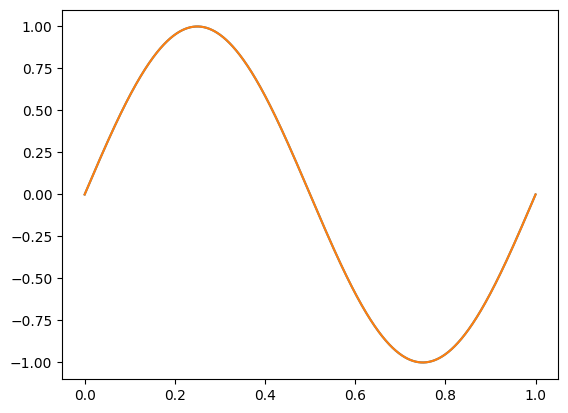

In [10]:

plt.plot(x,u_exact)
plt.plot(x,y_pred.detach().numpy())




After getting the training coefficients that fit the BCs we incorporate them in the bsplines2D

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
bc_coeff = torch.load('./results/diffusion/bc_coeff_20_3.pt')
# Add the homogeneous BCs for t=0
bc_coeffs = torch.cat([torch.tensor([0.0]), bc_coeff, torch.tensor([0.0])])
bc_coeffs.shape

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_103236\3570212726.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  bc_coeff = torch.load('./results/diffusion/bc_coeff_20_

torch.Size([20])

In [3]:
class bsplines2D:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_t = self.knot_vector.clone()

        # 2D interior domain trainable coefficients
        self.coeffs_trainable = torch.rand(n_basis-1, n_basis-2)

        # Define the coeff based on the Dirichlet boundary conditions.
        # IC at t=0
        # self.coeffs_row_0=torch.tensor([0.0, 0.3162,  0.8723,  1.1328,  0.4845, -0.4881, -1.1225, -0.8896, -0.3011,0.0])
        self.coeffs_row_0=bc_coeffs
        
        # BC 
        self.coeffs_rl = torch.tensor([0.0])
        self.coeffs_trainable.requires_grad_()
        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:

            #######Change#############
            #In degree 2 when I put = it gets bad
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            #######Change#############
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_t = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_t) for j in range(self.n_basis)])
        
        
        y = torch.zeros(x.shape[0])
        # Adding the internal domain bsplines
        for i in range(1,self.n_basis):
            for j in range(1,self.n_basis-1):
                y += self.coeffs_trainable[i-1, j-1] * self.B_t[i]*self.B_x[j]
        
        # Adding the IC 
        for i in range(self.n_basis):
            y += self.coeffs_row_0[i]*self.B_t[0]*self.B_x[i]

        #Adding BC to the left side
        for i in range(1,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[0]

        #Adding BC to the left side
        for i in range(1,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[self.n_basis-1]


        return y

In [4]:
torch.manual_seed(42)

# model = bsplines2D(10,3)
# If We dont get good fit, train the BC for 20,3 and use here 20,3
# model = bsplines2D(20,2)
model = bsplines2D(20,3)
model.coeffs_trainable.shape

torch.Size([19, 18])

In [5]:
colloc_points = 5000

# Reproducable input points
torch.manual_seed(42)

#X[:,0] is x and X[:,1] is time
#########Change###########
# X = 0.999*torch.rand(colloc_points,2)+0.001
X = torch.rand(colloc_points,2)
#########Change###########

X.requires_grad_(True)

tensor([[0.8823, 0.9150],
        [0.3829, 0.9593],
        [0.3904, 0.6009],
        ...,
        [0.9278, 0.5794],
        [0.8308, 0.2181],
        [0.9120, 0.4111]], requires_grad=True)

In [6]:
epochs = 10000
learning_rate=1e-3

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs_trainable], lr=learning_rate)
###########Changes#################

loss_vec = []
for epoch in range(epochs):
    ###########Changes#################
    optimizer.zero_grad()
    ###########Changes#################
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_t = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]

    # Residual loss
    res = u_t -0.03*u_xx 
    
    loss = torch.mean(res**2)
    
    loss.backward()
    ###########Changes#################
    optimizer.step()
    ###########Changes#################
    # Manually update parameters using the gradients
    # with torch.no_grad():
    #     model.coeffs_trainable -= learning_rate * model.coeffs_trainable.grad
    # # Zero the gradients after each update
    # model.coeffs_trainable.grad.zero_()
    # x.grad.zero_()
    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/10000], Loss: 90.06167602539062
Epoch [10/10000], Loss: 88.35660552978516
Epoch [15/10000], Loss: 86.68509674072266
Epoch [20/10000], Loss: 85.04855346679688
Epoch [25/10000], Loss: 83.44778442382812
Epoch [30/10000], Loss: 81.88326263427734
Epoch [35/10000], Loss: 80.3550796508789
Epoch [40/10000], Loss: 78.86314392089844
Epoch [45/10000], Loss: 77.40711975097656
Epoch [50/10000], Loss: 75.98648834228516
Epoch [55/10000], Loss: 74.60055541992188
Epoch [60/10000], Loss: 73.24855041503906
Epoch [65/10000], Loss: 71.92962646484375
Epoch [70/10000], Loss: 70.64289855957031
Epoch [75/10000], Loss: 69.38748168945312
Epoch [80/10000], Loss: 68.16249084472656
Epoch [85/10000], Loss: 66.96705627441406
Epoch [90/10000], Loss: 65.80032348632812
Epoch [95/10000], Loss: 64.66146850585938
Epoch [100/10000], Loss: 63.54966354370117
Epoch [105/10000], Loss: 62.46413040161133
Epoch [110/10000], Loss: 61.40409469604492
Epoch [115/10000], Loss: 60.368812561035156
Epoch [120/10000], Loss: 59.357

Post processing

In [ ]:
# Save loss
loss_vec_npy = np.array(loss_vec)
np.save(loss_vec_npy, './results/poisson/bsplines_loss.npy')

#Save model trainable parameters
params = { 'coeffs_trainable': model.coeffs_trainable }
torch.save(params, './results/poisson/model_bsplines.pth')

In [6]:
# Load model trainable parameters
model_s = bsplines2D(20,3)
loaded_params = torch.load('./results/diffusion/model_bsplines.pth')
model_s.coeffs_trainable = loaded_params['coeffs_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_103236\2293525841.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/diffusion/model_b

In [7]:
# Load loss
loss_bsplines_s = np.load('./results/diffusion/bsplines_loss.npy')

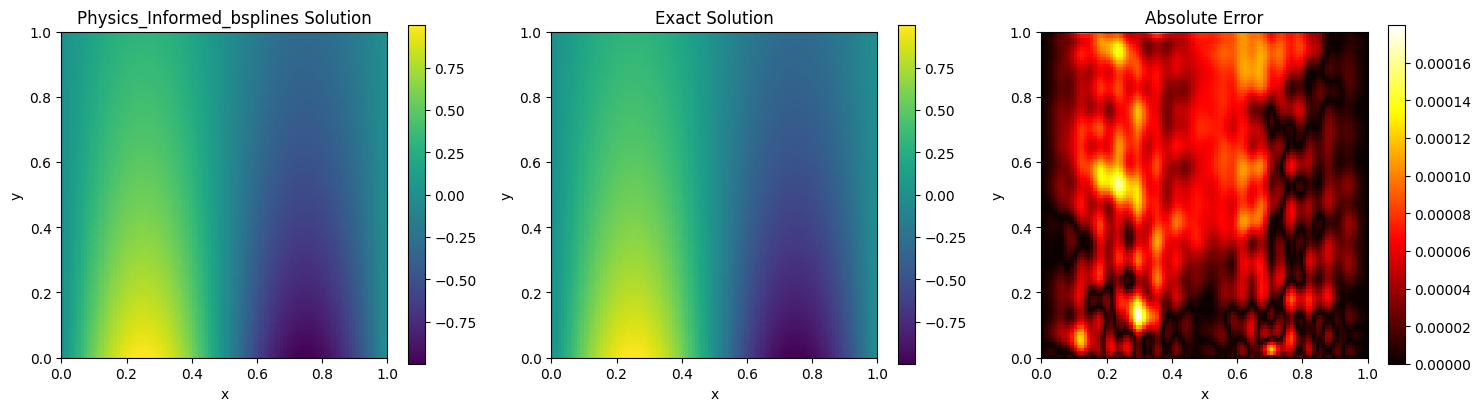

In [8]:
# 🔍 Evaluate on a grid
x = y = np.linspace(0, 1, 100)
Xg, Tg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)

# Prediction
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)

# ✅ Exact solution
u_exact = np.sin(2*np.pi * Xg) * np.exp(-np.pi**2 *0.03* Tg*4)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))
# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

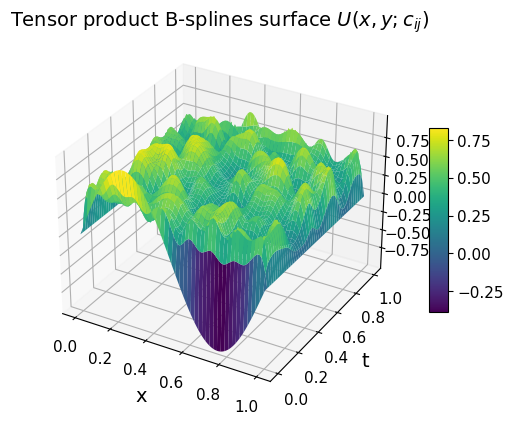

In [41]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)
# fig, axs = plt.subplots(1, 3, figsize=(15, 4))


# Plot surface
surf = ax.plot_surface(Xg, Yg, u_pred, cmap='viridis')  # Note the .T for correct orientation

# Add labels and colorbar
ax.set_title('Tensor product B-splines surface $U(x,y;c_{ij})$',fontsize=14)
ax.set_xlabel('x',fontsize=14)
ax.set_ylabel('t',fontsize=14)
ax.set_zlabel('u',fontsize=14)
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10).ax.tick_params(labelsize=11) 
ax.tick_params(axis='both', labelsize=11)
# plt.savefig("surface_DCIC_diffusion.pdf")
plt.show()

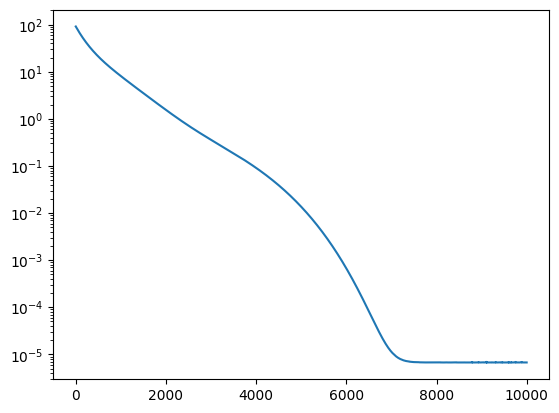

In [9]:
plt.plot(loss_bsplines_s)
plt.yscale('log')

PINN Solution

In [1]:

# First we are implementing hyperparameter tuning based on optuna with Tree-structured Parzen Estimator (TPE) algorithm.
import torch.autograd as autograd
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
import optuna
import random
torch.manual_seed(42)
# Device

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device( 'cpu')
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    # Force deterministic behavior in CuDNN (can slow training)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


alpha = 0.03  # diffusion coefficient
# PINN model
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.layers = nn.ModuleList()
        self.activation = nn.Tanh()
        for i in range(len(layers)-1):
            self.layers.append(nn.Linear(layers[i], layers[i+1]))

    def forward(self, x):
        for i in range(len(self.layers)-1):
            x = self.activation(self.layers[i](x))
        x = self.layers[-1](x)
        return x

def pde_residual(model, x_t):
    x_t.requires_grad_(True)
    u = model(x_t)

    grads = autograd.grad(u, x_t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0:1]
    u_t = grads[:, 1:2]

    u_xx = autograd.grad(u_x, x_t, grad_outputs=torch.ones_like(u_x), create_graph=True)[0][:, 0:1]

    return u_t - alpha * u_xx

def generate_training_points(n_interior, n_boundary, n_initial):
    # Interior points u(x,t)
    x_in = torch.rand(n_interior, 1)
    t_in = torch.rand(n_interior, 1)
    interior = torch.cat([x_in, t_in], dim=1)

    # Boundary points u(0,t)=u(1,t)
    t_b = torch.rand(n_boundary, 1)
    zeros = torch.zeros(n_boundary // 2, 1)
    ones = torch.ones(n_boundary // 2, 1)
    # half points right x=0,  half points left boundary x=1
    b1 = torch.cat([zeros, t_b[:n_boundary // 2]], dim=1)
    b2 = torch.cat([ones, t_b[n_boundary // 2:]], dim=1)
    boundary = torch.cat([b1, b2], dim=0)

    # Initial points u(x,0)
    x_i = torch.rand(n_initial, 1)
    t_i = torch.zeros(n_initial, 1)
    initial = torch.cat([x_i, t_i], dim=1)

    return interior, boundary, initial


# # Train the model
# layers = [2, 20, 20, 20, 1]
# model = PINN(layers).to(device)
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# X_in, X_b = generate_training_points(5000, 50)


# Hyperparameter tuning 

def objective(trial):
    # Sample hyperparameters
    n_layers = trial.suggest_int("n_layers", 2, 5)
    n_neurons = trial.suggest_int("n_neurons", 10, 100)
    learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-2)

    # Build layers list
    layers = [2] + [n_neurons] * n_layers + [1]
    model = PINN(layers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


    # Generate training data
    n_interior, n_boundary, n_initial = 5000, 1000, 1000
    interior, boundary, initial = generate_training_points(n_interior, n_boundary, n_initial)
    interior, boundary, initial = interior.to(device), boundary.to(device), initial.to(device)

    # Train for a small number of epochs
    for epoch in range(1000):
        optimizer.zero_grad()
        
        f_interior = pde_residual(model, interior)
        loss_pde = torch.mean(f_interior**2)

        u_boundary = model(boundary)
        loss_bc = torch.mean(u_boundary**2)

        u_initial_pred = model(initial)
        u_initial_true = torch.sin(2 * np.pi * initial[:, 0:1])
        loss_ic = torch.mean((u_initial_pred - u_initial_true) ** 2)

        loss = loss_pde + loss_bc + loss_ic
        loss.backward()
        optimizer.step()

    return loss.item()

# ---- Run Optuna study ---- #
if __name__ == "__main__":
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=20)

    print("Best trial:")
    trial = study.best_trial
    print(f"  Loss: {trial.value}")
    print("  Best hyperparameters:")
    for key, value in trial.params.items():
        print(f"    {key}: {value}")

c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2025-07-16 09:18:32,569] A new study created in memory with name: no-name-988216f7-9ea2-4540-a93b-5835d9d1d4ca
C:\Users\Polydoras\AppData\Local\Temp\ipykernel_12172\750980083.py:93: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-2)
c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\torch\autograd\graph.py:769: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work

KeyboardInterrupt: 

In [10]:
# Now train with the tuned hyperparameters

import torch
import torch.nn as nn
import torch.autograd as autograd
import numpy as np
import matplotlib.pyplot as plt


torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
alpha = 0.03  # diffusion coefficient

class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.layers = nn.ModuleList()
        self.activation = nn.Tanh()
        for i in range(len(layers)-1):
            self.layers.append(nn.Linear(layers[i], layers[i+1]))

    def forward(self, x):
        for i in range(len(self.layers)-1):
            x = self.activation(self.layers[i](x))
        x = self.layers[-1](x)
        return x

In [2]:


def pde_residual(model, x_t):
    x_t.requires_grad_(True)
    u = model(x_t)

    grads = autograd.grad(u, x_t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0:1]
    u_t = grads[:, 1:2]

    u_xx = autograd.grad(u_x, x_t, grad_outputs=torch.ones_like(u_x), create_graph=True)[0][:, 0:1]

    return u_t - alpha * u_xx

def generate_training_points(n_interior, n_boundary, n_initial):
    # Interior points u(x,t)
    x_in = torch.rand(n_interior, 1)
    t_in = torch.rand(n_interior, 1)
    interior = torch.cat([x_in, t_in], dim=1)

    # Boundary points u(0,t)=u(1,t)
    t_b = torch.rand(n_boundary, 1)
    zeros = torch.zeros(n_boundary // 2, 1)
    ones = torch.ones(n_boundary // 2, 1)
    # half points right x=0,  half points left boundary x=1
    b1 = torch.cat([zeros, t_b[:n_boundary // 2]], dim=1)
    b2 = torch.cat([ones, t_b[n_boundary // 2:]], dim=1)
    boundary = torch.cat([b1, b2], dim=0)

    # Initial points u(x,0)
    x_i = torch.rand(n_initial, 1)
    t_i = torch.zeros(n_initial, 1)
    initial = torch.cat([x_i, t_i], dim=1)

    return interior, boundary, initial

# model = PINN([2, 20, 20, 20, 1]).to(device)
#####Changes###########
model = PINN([2, 99, 99, 99, 99, 99, 1]).to(device)
# model = PINN([2, 73, 73, 73, 73, 73, 1]).to(device)
learning_rate = 1e-4
#####Changes###########

# learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
n_iter = 100000
n_interior, n_boundary, n_initial = 5000, 1000, 1000
loss_vec = []
for it in range(n_iter):
    interior, boundary, initial = generate_training_points(n_interior, n_boundary, n_initial)
    interior, boundary, initial = interior.to(device), boundary.to(device), initial.to(device)

    optimizer.zero_grad()

    f_interior = pde_residual(model, interior)
    loss_pde = torch.mean(f_interior**2)

    u_boundary = model(boundary)
    loss_bc = torch.mean(u_boundary**2)

    u_initial_pred = model(initial)
    u_initial_true = torch.sin(2 * np.pi * initial[:, 0:1])
    loss_ic = torch.mean((u_initial_pred - u_initial_true) ** 2)

    loss = loss_pde + loss_bc + loss_ic
    loss.backward()
    optimizer.step()

    loss_vec.append(loss.item())

    if it % 500 == 0:
        print(f"Iteration {it}: Loss = {loss.item():.6f}")

print("Training finished.")

# def plot_solution(model, t_vals=[0.0, 0.25, 0.5, 0.75, 1.0]):
#     x = torch.linspace(0,1,100).unsqueeze(1).to(device)
#     plt.figure(figsize=(8,6))
#     for t in t_vals:
#         t_tensor = torch.full_like(x, t)
#         xt = torch.cat([x, t_tensor], dim=1)
#         with torch.no_grad():
#             u_pred = model(xt).cpu().numpy()
#         plt.plot(x.cpu().numpy(), u_pred, label=f't={t}')
#     plt.xlabel('x')
#     plt.ylabel('u(x,t)')
#     plt.title('PINN solution to 1D diffusion equation')
#     plt.legend()
#     plt.show()




c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\torch\autograd\graph.py:769: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Iteration 0: Loss = 0.481245
Iteration 500: Loss = 0.087365
Iteration 1000: Loss = 0.003336
Iteration 1500: Loss = 0.002031
Iteration 2000: Loss = 0.001764
Iteration 2500: Loss = 0.001486
Iteration 3000: Loss = 0.001354
Iteration 3500: Loss = 0.001187
Iteration 4000: Loss = 0.000973
Iteration 4500: Loss = 0.001026
Iteration 5000: Loss = 0.000740
Iteration 5500: Loss = 0.000589
Iteration 6000: Loss = 0.000527
Iteration 6500: Loss = 0.000475
Iteration 7000: Loss = 0.000436
Iteration 7500: Loss = 0.000445
Iteration 8000: Loss = 0.000385
Iteration 8500: Loss = 0.000305
Iteration 9000: Loss = 0.000307
Iteration 9500: Loss = 0.000263
Iteration 10000: Loss = 0.000277
Iteration 10500: Loss = 0.000241
Iteration 11000: Loss = 0.000198
Iteration 11500: Loss = 0.000191
Iteration 12000: Loss = 0.000161
Iteration 12500: Loss = 0.000185
Iteration 13000: Loss = 0.000187
Iteration 13500: Loss = 0.000139
Iteration 14000: Loss = 0.000124
Iteration 14500: Loss = 0.000184
Iteration 15000: Loss = 0.000105
I

In [6]:
# Transform list of tensors to numpy array
loss_vec_npy = np.array(loss_vec)
np.save('./results/diffusion/pinn_loss.npy',loss_vec_npy)


In [3]:
#Save model trainable parameters
torch.save(model.state_dict(), './results/diffusion/model_pinn.pth')

In [11]:
layers = [2, 99, 99, 99, 99, 99, 1]
model_ps = PINN(layers)  # same architecture as used before
model_ps.load_state_dict(torch.load('./results/diffusion/model_pinn.pth'))
model_ps.eval()  # if you're evaluating


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_103236\3751028392.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_ps.load_state_dict(torch.load('./results/diffusio

PINN(
  (layers): ModuleList(
    (0): Linear(in_features=2, out_features=99, bias=True)
    (1-4): 4 x Linear(in_features=99, out_features=99, bias=True)
    (5): Linear(in_features=99, out_features=1, bias=True)
  )
  (activation): Tanh()
)

In [12]:
loss_pinn = np.load('./results/diffusion/pinn_loss.npy')

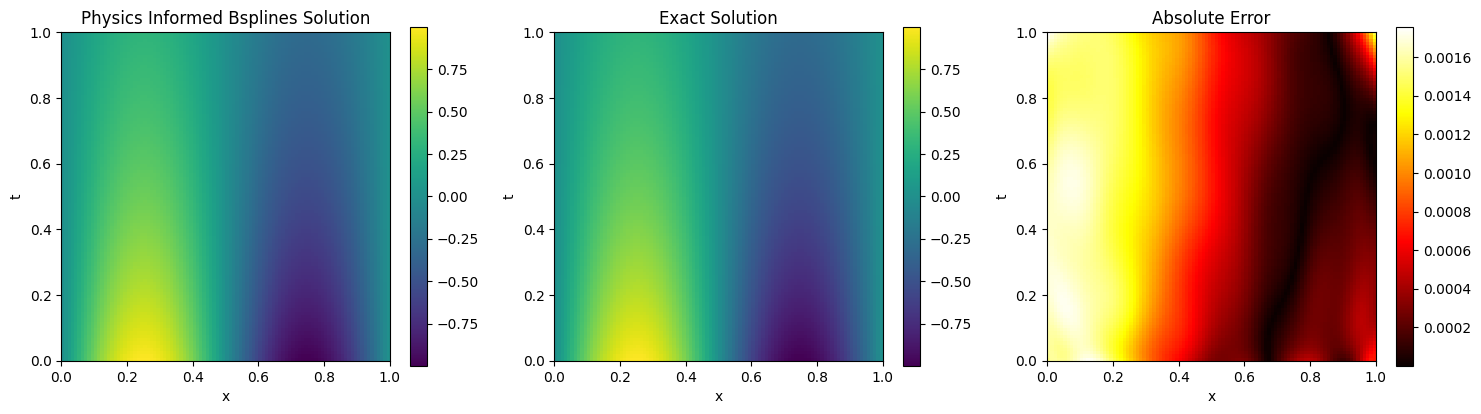

In [15]:
x = y = np.linspace(0, 1, 100)
X, Y = np.meshgrid(x, y)
XY = np.vstack([X.ravel(), Y.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
model_ps.cpu()
with torch.no_grad():
    u_pred = model_ps.forward(XY_torch).numpy().reshape(X.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

u_exact = np.sin(2*np.pi * X) * np.exp(-np.pi**2 *0.03* Y*4)

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("Physics Informed Bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("t")

plt.tight_layout()
plt.show()

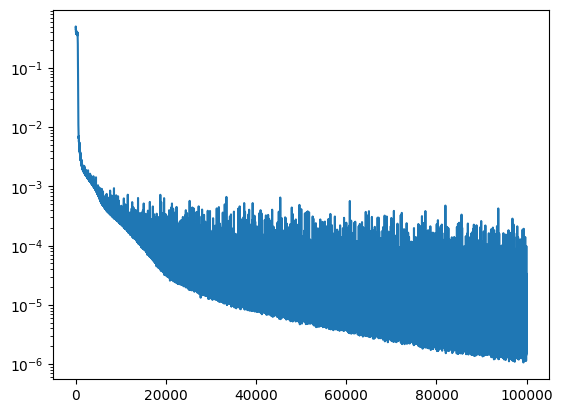

In [16]:
plt.plot(loss_pinn)
plt.yscale('log')

Postprocessing

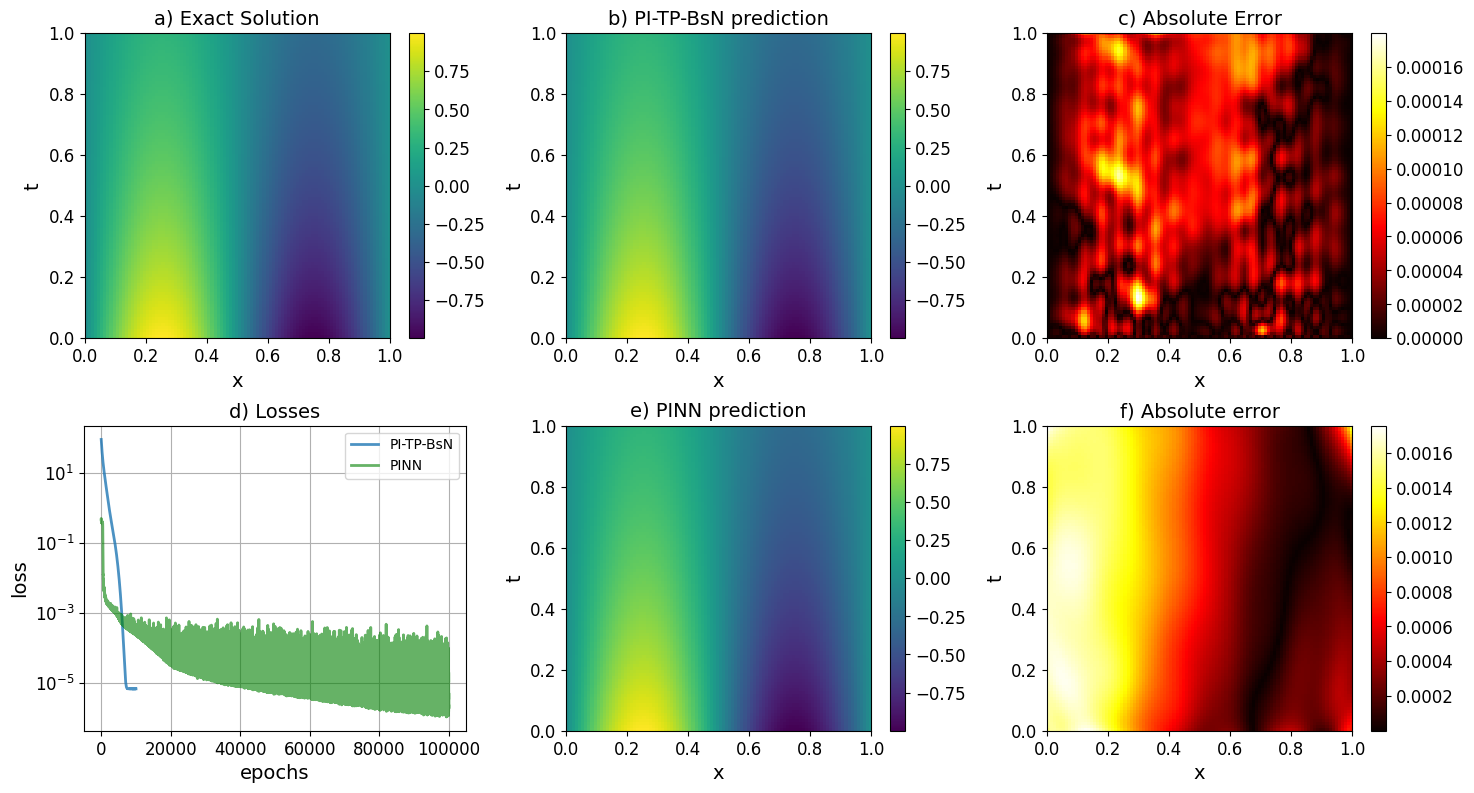

In [17]:
x = y = np.linspace(0, 1, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)

with torch.no_grad():
    u_predp = model_ps.forward(XY_torch).numpy().reshape(Xg.shape)

fig, axs = plt.subplots(2, 3, figsize=(15, 8))

u_exact = np.sin(2*np.pi * Xg) * np.exp(-np.pi**2 *0.03* Yg*4)

# Exact solution
im0 = axs[0,0].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0,0].set_title("a) Exact Solution",fontsize=14)
axs[0,0].set_xlabel("x",fontsize=14)
axs[0,0].set_ylabel("t",fontsize=14)
axs[0,0].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im0, ax=axs[0,0])
cbar.ax.tick_params(labelsize=12) 

# B-splines solution
im1 = axs[0, 1].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0,1].set_title("b) PI-TP-BsN prediction",fontsize=14)
axs[0,1].set_xlabel("x",fontsize=14)
axs[0,1].set_ylabel("t",fontsize=14)
axs[0,1].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im1, ax=axs[0, 1])
cbar.ax.tick_params(labelsize=12) 

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[0, 2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[0,2].set_title("c) Absolute Error",fontsize=14)
axs[0,2].set_xlabel("x",fontsize=14)
axs[0,2].set_ylabel("t",fontsize=14)
axs[0,2].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im2, ax=axs[0, 2])
cbar.ax.tick_params(labelsize=12) 

# Losses
x_a = np.arange(len(loss_bsplines_s))
x_b = np.arange(len(loss_pinn))
axs[1, 0].plot(x_a, loss_bsplines_s, label='PI-TP-BsN', alpha=0.8,linewidth=2)
axs[1, 0].plot(x_b, loss_pinn, label='PINN', alpha=0.6, color='green',linewidth=2)
axs[1, 0].legend()
axs[1, 0].set_yscale('log')
axs[1,0].set_title("d) Losses",fontsize=14)
axs[1,0].set_xlabel("epochs",fontsize=14)
axs[1,0].set_ylabel("loss",fontsize=14)
axs[1,0].tick_params(axis='both', labelsize=12)
axs[1,0].grid(True)
# cbar = fig.colorbar(im3, ax=axs[1, 0])
# cbar.ax.tick_params(labelsize=12) 

# Absolute error
im4 = axs[1, 1].imshow(u_predp, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1,1].set_title("e) PINN prediction",fontsize=14)
axs[1,1].set_xlabel("x",fontsize=14)
axs[1,1].set_ylabel("t",fontsize=14)
axs[1,1].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im4, ax=axs[1, 1])
cbar.ax.tick_params(labelsize=12) 

# Exact solution
error = np.abs(u_predp - u_exact)
im5 = axs[1, 2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[1, 2].set_title("f) Absolute error",fontsize=14)
axs[1, 2].set_xlabel("x",fontsize=14)
axs[1, 2].set_ylabel("t",fontsize=14)
axs[1, 2].tick_params(axis='both', labelsize=12)
cbar = fig.colorbar(im5, ax=axs[1, 2])
cbar.ax.tick_params(labelsize=12) 


# for ax in axs:
#     ax.set_xlabel("x",fontsize=14)
#     ax.set_ylabel("y",fontsize=14)
#     ax.tick_params(axis='both', labelsize=12)
plt.tight_layout()
# fig.savefig("diffusion1.pdf", dpi=300)
plt.show()

In [56]:
loss_pinn.shape

(100000,)

In [59]:
loss_pinn[-1]

3.6628730413212907e-06

In [18]:
np.sqrt(np.sum((u_pred - u_exact)**2))/np.sqrt(np.sum(u_exact**2))

0.00011996709218368054

In [20]:
np.sqrt(np.sum((u_predp - u_exact)**2))/np.sqrt(np.sum(u_exact**2))

0.002185238165240531

In [12]:
loss_bsplines_s[-1]

6.74715420245775e-06

In [13]:
loss_pinn[-1]

3.6628730413212907e-06

In [22]:
re = np.sqrt(np.sum((u_pred - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
re

0.00011996709218368054

In [23]:
re_p = np.sqrt(np.sum((u_predp - u_exact)**2))/np.sqrt(np.sum(u_exact**2))
re_p

0.002185238165240531

In [24]:
(re_p-re)/re_p

0.9451011363008682

In [20]:
error = np.abs(u_pred - u_exact)
error.max()


0.00017987425479526475

In [21]:
errorp = np.abs(u_predp - u_exact)
errorp.max()


0.0017565400339663029

In [ ]:
errorp.max()/error.max()

89.47244220521722

In [19]:
import math

a = 0.01
b = 0.003
delta_order = abs(math.log10(errorp.max()) - math.log10(error.max()))
print(f"Difference in orders of magnitude: {delta_order}")


Difference in orders of magnitude: 0.9896890447092694
